Imports

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import time
import numpy as np
import matplotlib.pyplot as plt

Modelo estritamente igual ao artigo, sem a adição dos centros treináveis. A ideia é comparar o desempenho do modelo com e sem os centros treináveis.

In [13]:
class XNetLayer(nn.Module):
    def __init__(self, in_features, num_basis):
        super(XNetLayer, self).__init__()
        self.num_basis = num_basis

        self.d = nn.Parameter(
            torch.rand(num_basis) * 0.5 + 0.01 
        )
        self.lambda1 = nn.Parameter(torch.randn(num_basis))
        self.lambda2 = nn.Parameter(torch.randn(num_basis))
        self.output_linear = nn.Linear(num_basis, 1)
    def forward(self, x):
            denom = x**2 + self.d.unsqueeze(0)**2
            phi = (
                self.lambda1.unsqueeze(0) * x / denom
                +
                self.lambda2.unsqueeze(0) / denom
            )
            return self.output_linear(phi)


MLP tradicional com 4/3 do número de unidades escondidas do XNet, e apenas uma camada escondida, para manter a mesma capacidade representacional.

In [28]:
class StandardMLP(nn.Module):
    def __init__(self, in_features, hidden_dim):
        super(StandardMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
        
    def forward(self, x):
        return self.network(x)



In [4]:
class MLP8(nn.Module):
    def __init__(self, in_features, hidden_dim):
        super(MLP8, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1)
        )
        
    def forward(self, x):
        return self.network(x)

In [6]:
class ResidualBlock(nn.Module):
    def __init__(self, hidden_dim):
        super(ResidualBlock, self).__init__()
        self.linear1 = nn.Linear(hidden_dim, hidden_dim)
        self.softplus1 = nn.Softplus() # Utilizando SoftPlus conforme o artigo
        self.linear2 = nn.Linear(hidden_dim, hidden_dim)
        self.softplus2 = nn.Softplus()

    def forward(self, x):
        # Caminho principal (Transformação)
        residual = self.linear1(x)
        residual = self.softplus1(residual)
        residual = self.linear2(residual)
        
        # Skip Connection (Soma a entrada original ao resultado)
        out = x + residual
        return self.softplus2(out)

class ResidualMLP(nn.Module):
    def __init__(self, in_features=1, hidden_dim=8, num_blocks=2):
        super(ResidualMLP, self).__init__()
        
        # Projeta a entrada (1D) para a dimensão oculta (8D)
        self.input_layer = nn.Sequential(
            nn.Linear(in_features, hidden_dim),
            nn.Softplus()
        )
        
        # Cria os blocos residuais
        self.blocks = nn.ModuleList([ResidualBlock(hidden_dim) for _ in range(num_blocks)])
        
        # Projeta de volta para a saída (1D)
        self.output_layer = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        out = self.input_layer(x)
        for block in self.blocks:
            out = block(out)
        return self.output_layer(out)

Código xNet com a lógica igual à do artigo com a adição dos centros treináveis

In [22]:


# 1. Definição da Arquitetura XNet (Baseada no Artigo)
class XNetLayerCentred(nn.Module):
    def __init__(self, in_features, num_basis):
        super(XNetLayerCentred, self).__init__()
        self.num_basis = num_basis
        
        self.d = nn.Parameter(torch.rand(num_basis) * 0.5 + 0.1)
        self.lambda1 = nn.Parameter(torch.randn(num_basis))
        self.lambda2 = nn.Parameter(torch.randn(num_basis))
        self.centers = nn.Parameter(torch.linspace(-1.0, 1.0, num_basis))
        self.output_linear = nn.Linear(num_basis, 1)

    def forward(self, x):
        x_shifted = x - self.centers.unsqueeze(0)
        denom = x_shifted**2 + self.d.unsqueeze(0)**2
        phi = (self.lambda1.unsqueeze(0) * x_shifted) / denom + self.lambda2.unsqueeze(0) / denom
        return self.output_linear(phi)



In [19]:


# 1. Definição da Arquitetura XNet (Baseada no Artigo)
class XNetLayerCentred(nn.Module):
    def __init__(self, in_features, num_basis):
        super(XNetLayerCentred, self).__init__()
        self.num_basis = num_basis
        
        self.d = nn.Parameter(torch.rand(num_basis) * 0.5 + 0.1)
        self.lambda1 = nn.Parameter(torch.randn(num_basis))
        self.lambda2 = nn.Parameter(torch.randn(num_basis))
        self.centers = nn.Parameter(torch.linspace(-1.0, 1.0, num_basis))
        # self.output_linear = nn.Linear(num_basis, 1)
        self.bias = nn.Parameter(torch.tensor(1.0))
    def forward(self, x):
        x_shifted = x - self.centers.unsqueeze(0)
        denom = x_shifted**2 + self.d.unsqueeze(0)**2
        phi = (self.lambda1.unsqueeze(0) * x_shifted) / denom + self.lambda2.unsqueeze(0) / denom
        return torch.sum(phi, dim=1, keepdim=True)+self.bias    



Inicialização e treinamento

In [31]:
def f(x):
    return torch.sin(10 * np.pi * x) * torch.exp(-x**2)
    # return x**8 + x**2+3

In [9]:
def train_model(model, x_train, y_train, epochs, limit,  lr, tol):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    final_loss = None
    final_epoch = None
    losses = []
    predictions = []

    print(f"\nStarting training of model {model.__class__.__name__} for {epochs} epochs with learning rate {lr} and tolerance {tol}")
    start_time = time.time()
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(x_train)
        loss = criterion(outputs, y_train)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        if loss.item() < tol:
            print(f"Converged at epoch {epoch} with loss {loss.item()}")
            break

        if epoch % 1000 == 0:
            print(f"Epoch [{epoch}/{epochs}], Loss: {loss.item():.6f}")
            predictions.append(outputs.detach().numpy())

        if time.time() - start_time > limit:
            print("Training stopped due to time limit.")
            final_loss = loss.item()
            final_epoch = epoch
            predictions.append(outputs.detach().numpy())
            break
        final_loss = loss.item()
        final_epoch = epoch

    end_time = time.time()
    print(f"Training completed in {end_time - start_time:.2f} seconds.")
    return model, end_time - start_time, final_loss, final_epoch, losses, predictions

In [29]:
# 3. Definição do Problema
torch.manual_seed(42)
x_train = torch.linspace(-1, 1, 1000).unsqueeze(1)
y_train = f(x_train)

epochs = 100000  
lr = 0.001
hidden_units = 100  
tol = 1e-5
limit = 20

mlp = StandardMLP(in_features=1, hidden_dim=int(hidden_units))
xnet = XNetLayer(in_features=1, num_basis=int(hidden_units*3/4))
xnet_centred = XNetLayerCentred(in_features=1, num_basis=int(hidden_units*3/5))
mlp8 = MLP8(in_features=1, hidden_dim=int(hidden_units*3/4))
residual_mlp = ResidualMLP(in_features=1, hidden_dim=hidden_units, num_blocks=2)

# printar o número de parametros de cada modelo
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

display(f"Number of parameters in MLP: {count_parameters(mlp)}")
display(f"Number of parameters in XNet: {count_parameters(xnet)}")
display(f"Number of parameters in XNet Centred: {count_parameters(xnet_centred)}")
display(f"Number of parameters in MLP8: {count_parameters(mlp8)}")
display(f"Number of parameters in Residual MLP: {count_parameters(residual_mlp)}")


'Number of parameters in MLP: 301'

'Number of parameters in XNet: 301'

'Number of parameters in XNet Centred: 301'

'Number of parameters in MLP8: 17326'

'Number of parameters in Residual MLP: 40701'

In [24]:
model_xnet, time_xnet, loss_xnet, epoch_xnet, losses_xnet, predictions_xnet = train_model(xnet, x_train, y_train, epochs, limit, lr, tol)
display(f"XNet - Final Loss: {loss_xnet:.6f}, Epochs: {epoch_xnet}, Time: {time_xnet:.2f}s")


Starting training of model XNetLayer for 100000 epochs with learning rate 0.001 and tolerance 1e-05
Epoch [0/100000], Loss: 1233.730225
Epoch [1000/100000], Loss: 0.273396
Epoch [2000/100000], Loss: 0.259616
Epoch [3000/100000], Loss: 0.250635
Epoch [4000/100000], Loss: 0.243657
Epoch [5000/100000], Loss: 0.239282
Epoch [6000/100000], Loss: 0.236642
Epoch [7000/100000], Loss: 0.234756


KeyboardInterrupt: 

In [25]:
model_xnet_centred, time_xnet_centred, loss_xnet_centred, epoch_xnet_centred, losses_xnet_centred, predictions_xnet_centred = train_model(xnet_centred, x_train, y_train, epochs, limit, lr, tol)
display(f"XNet Centred - Final Loss: {loss_xnet_centred:.6f}, Epochs: {epoch_xnet_centred}, Time: {time_xnet_centred:.2f}s")


Starting training of model XNetLayerCentred for 100000 epochs with learning rate 0.001 and tolerance 1e-05
Epoch [0/100000], Loss: 6.031426
Epoch [1000/100000], Loss: 0.057014
Epoch [2000/100000], Loss: 0.002508
Epoch [3000/100000], Loss: 0.000907
Epoch [4000/100000], Loss: 0.001020
Epoch [5000/100000], Loss: 0.000401
Epoch [6000/100000], Loss: 0.000338
Epoch [7000/100000], Loss: 0.000269
Epoch [8000/100000], Loss: 0.000226
Epoch [9000/100000], Loss: 0.000200
Training stopped due to time limit.
Training completed in 20.00 seconds.


'XNet Centred - Final Loss: 0.000186, Epochs: 9136, Time: 20.00s'

In [30]:
model_mlp, time_mlp, loss_mlp, epoch_mlp, losses_mlp, predictions_mlp = train_model(mlp, x_train, y_train, epochs, limit, lr, tol)
display(f"MLP - Final Loss: {loss_mlp:.6f}, Epochs: {epoch_mlp}, Time: {time_mlp:.2f}s")


Starting training of model StandardMLP for 100000 epochs with learning rate 0.001 and tolerance 1e-05
Epoch [0/100000], Loss: 0.363019
Epoch [1000/100000], Loss: 0.286555
Epoch [2000/100000], Loss: 0.249033
Epoch [3000/100000], Loss: 0.193160
Epoch [4000/100000], Loss: 0.154525
Epoch [5000/100000], Loss: 0.129809
Epoch [6000/100000], Loss: 0.113564
Epoch [7000/100000], Loss: 0.102669
Epoch [8000/100000], Loss: 0.095180
Epoch [9000/100000], Loss: 0.089866
Epoch [10000/100000], Loss: 0.086126
Epoch [11000/100000], Loss: 0.083038
Epoch [12000/100000], Loss: 0.080720
Epoch [13000/100000], Loss: 0.078852
Epoch [14000/100000], Loss: 0.077317
Epoch [15000/100000], Loss: 0.076119
Training stopped due to time limit.
Training completed in 20.00 seconds.


'MLP - Final Loss: 0.075758, Epochs: 15293, Time: 20.00s'

In [ ]:
model_mlp8, time_mlp8, loss_mlp8, epoch_mlp8, losses_mlp8, predictions_mlp8 = train_model(mlp8, x_train, y_train, epochs, limit, lr, tol)
display(f"MLP8 - Final Loss: {loss_mlp8:.6f}, Epochs: {epoch_mlp8}, Time: {time_mlp8:.2f}s")


Starting training of model MLP8 for 100000 epochs with learning rate 0.001 and tolerance 1e-05
Epoch [0/100000], Loss: 0.299386
Epoch [1000/100000], Loss: 0.004718
Epoch [2000/100000], Loss: 0.000301
Epoch [3000/100000], Loss: 0.000352
Epoch [4000/100000], Loss: 0.009656
Epoch [5000/100000], Loss: 0.000733
Epoch [6000/100000], Loss: 0.000178
Training stopped due to time limit.
Training completed in 20.00 seconds.


'MLP8 - Final Loss: 0.001780, Epochs: 6673, Time: 20.00s'

: 

In [40]:
model_mlp_residual, time_mlp_residual, loss_mlp_residual, epoch_mlp_residual, losses_mlp_residual, predictions_mlp_residual = train_model(mlp, x_train, y_train, epochs, limit, lr, tol)
display(f"MLP_residual - Final Loss: {loss_mlp_residual:.6f}, Epochs: {epoch_mlp_residual}, Time: {time_mlp_residual:.2f}s")



Starting training of model StandardMLP for 100000 epochs with learning rate 0.001 and tolerance 1e-05
Epoch [0/100000], Loss: 0.363019
Epoch [1000/100000], Loss: 0.286555
Epoch [2000/100000], Loss: 0.248967
Epoch [3000/100000], Loss: 0.192994
Epoch [4000/100000], Loss: 0.154369
Epoch [5000/100000], Loss: 0.129684
Epoch [6000/100000], Loss: 0.113533
Epoch [7000/100000], Loss: 0.102701
Epoch [8000/100000], Loss: 0.095188
Epoch [9000/100000], Loss: 0.089897
Epoch [10000/100000], Loss: 0.086025
Epoch [11000/100000], Loss: 0.083058
Epoch [12000/100000], Loss: 0.080756
Epoch [13000/100000], Loss: 0.078890
Epoch [14000/100000], Loss: 0.077356
Epoch [15000/100000], Loss: 0.076078
Epoch [16000/100000], Loss: 0.075025
Epoch [17000/100000], Loss: 0.074136
Epoch [18000/100000], Loss: 0.073369
Epoch [19000/100000], Loss: 0.072736
Epoch [20000/100000], Loss: 0.072184
Epoch [21000/100000], Loss: 0.071735
Epoch [22000/100000], Loss: 0.071268
Epoch [23000/100000], Loss: 0.070908
Training stopped due t

'MLP_residual - Final Loss: 0.070737, Epochs: 23522, Time: 20.00s'

In [ ]:
ratio = max(loss_xnet, loss_mlp) / min(loss_xnet, loss_mlp)
ratio_centred = max(loss_xnet_centred, loss_mlp) / min(loss_xnet_centred, loss_mlp)

display(f"Razão dos erros de treinamento: {ratio:.2f}, maior erro: {max(loss_xnet, loss_mlp):.6f}, menor erro: {min(loss_xnet, loss_mlp):.6f}")
display(f"Razão dos erros de treinamento (XNet Centred): {ratio_centred:.2f}, maior erro: {max(loss_xnet_centred, loss_mlp):.6f}, menor erro: {min(loss_xnet_centred, loss_mlp):.6f}")

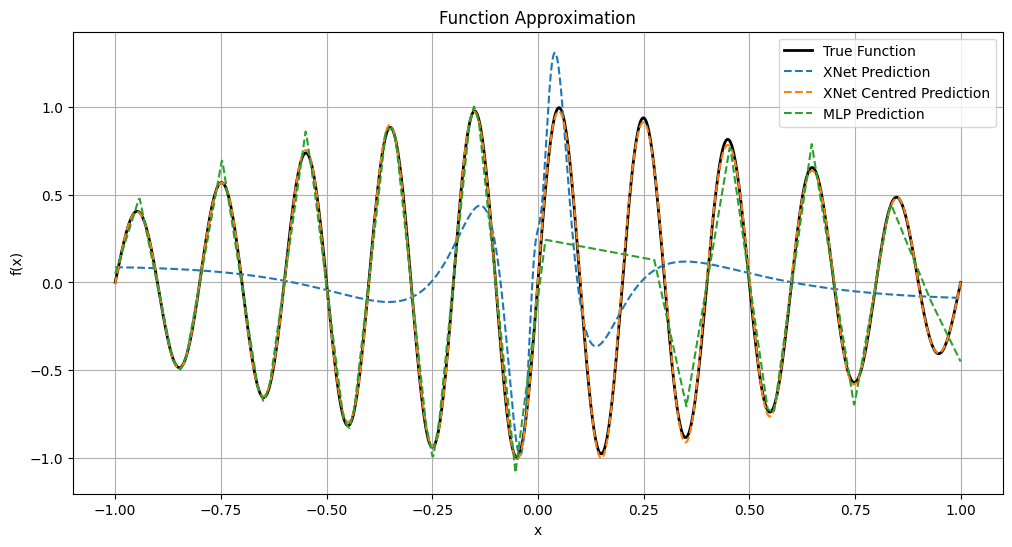

In [22]:
# plotar o gráfico da função real e das previsões dos modelos
x_test = torch.linspace(-1, 1, 1000).unsqueeze(1)
y_test = f(x_test)
y_pred_xnet = model_xnet(x_test).detach()
y_pred_xnet_centred = model_xnet_centred(x_test).detach()
y_pred_mlp = model_mlp(x_test).detach()

plt.figure(figsize=(12, 6))
plt.plot(x_test.numpy(), y_test.numpy(), label='True Function', color='black', linewidth=2)
plt.plot(x_test.numpy(), y_pred_xnet.numpy(), label='XNet Prediction', linestyle='--')
plt.plot(x_test.numpy(), y_pred_xnet_centred.numpy(), label='XNet Centred Prediction', linestyle='--')
plt.plot(x_test.numpy(), y_pred_mlp.numpy(), label='MLP Prediction', linestyle='--')
plt.title('Function Approximation')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend()
plt.grid()
plt.show()

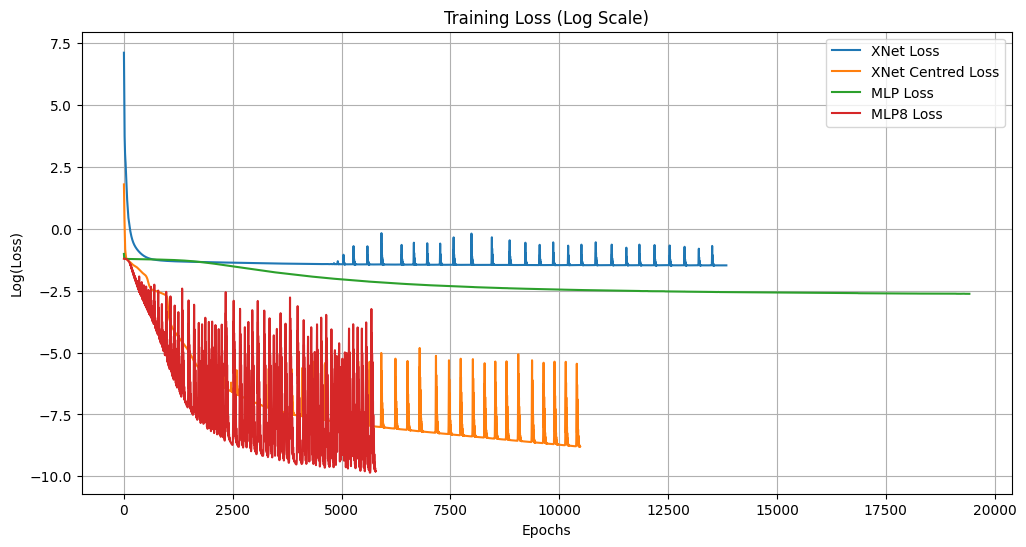

In [30]:
# plotar o gráfico da perda log ao longo das épocas para cada modelo
plt.figure(figsize=(12, 6))
plt.plot(np.log(losses_xnet), label='XNet Loss')
plt.plot(np.log(losses_xnet_centred), label='XNet Centred Loss')
plt.plot(np.log(losses_mlp), label='MLP Loss')
plt.plot(np.log(losses_mlp8), label='MLP8 Loss')
plt.title('Training Loss (Log Scale)')
plt.xlabel('Epochs')
plt.ylabel('Log(Loss)')
plt.legend()
plt.grid()
plt.show()

Plotagem da evolução das predições do modelo ao longo das épocas de treinamento, para ver como o modelo se aproxima da função alvo.

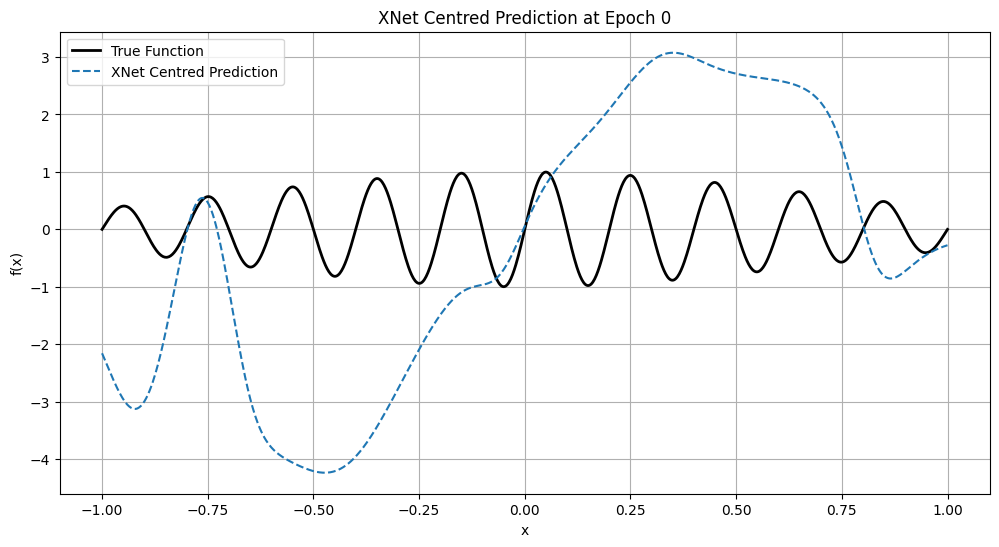

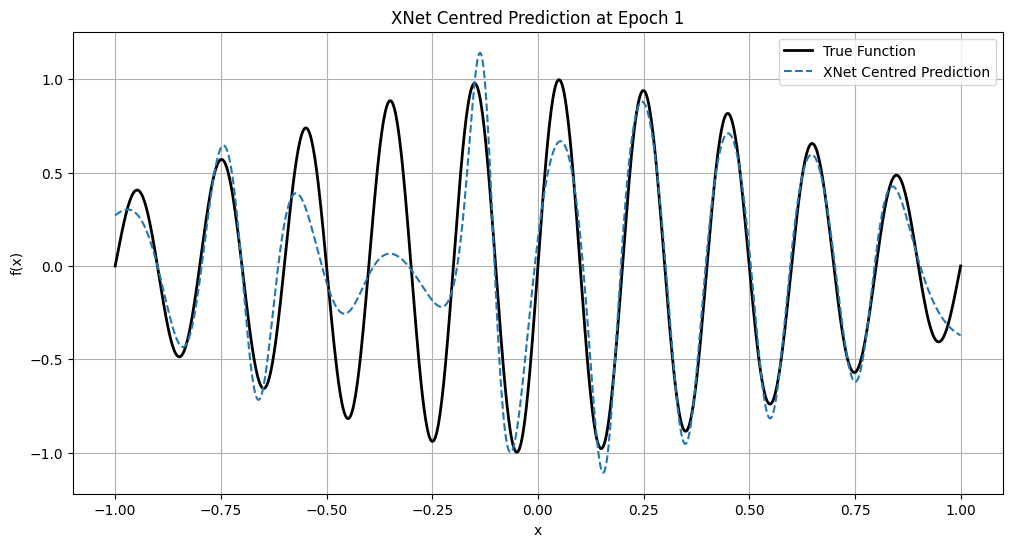

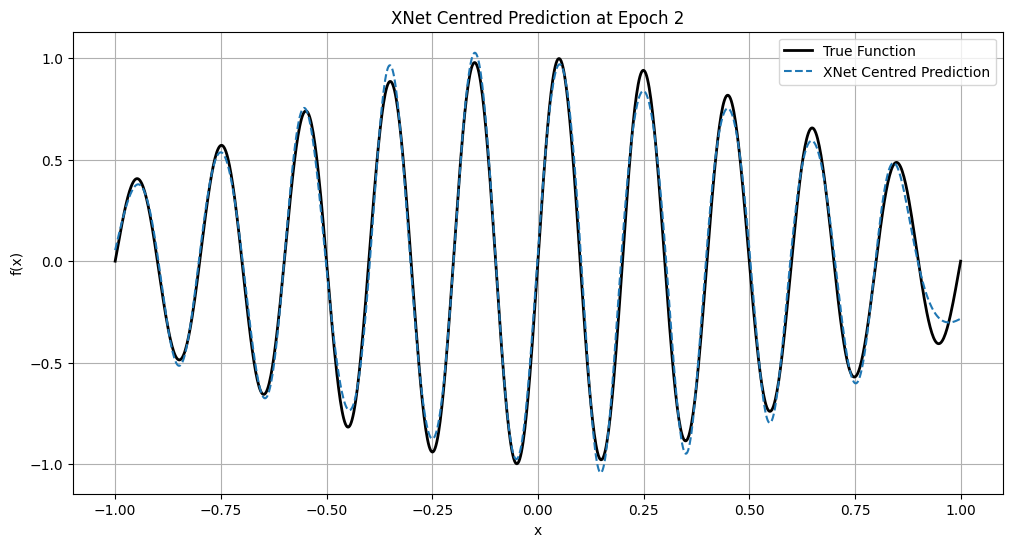

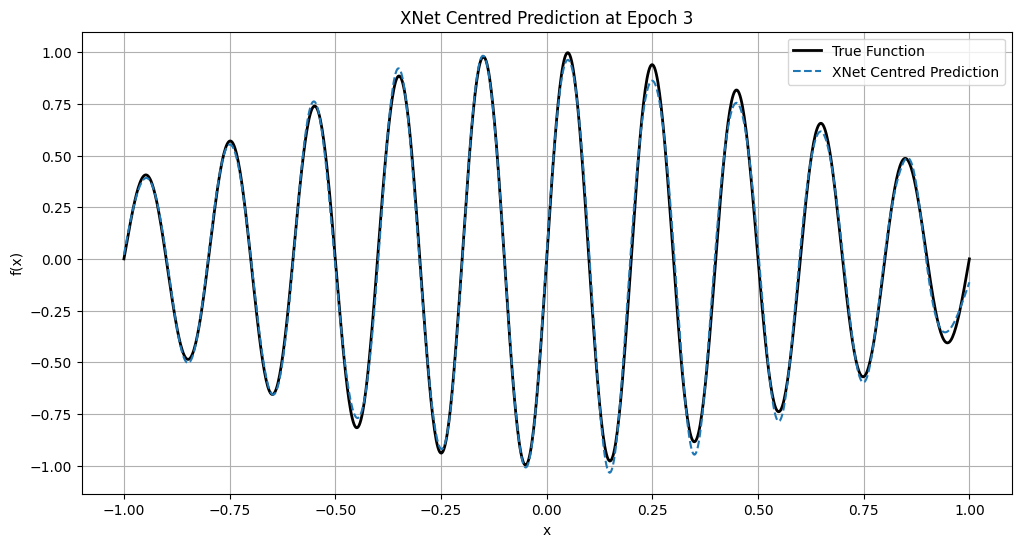

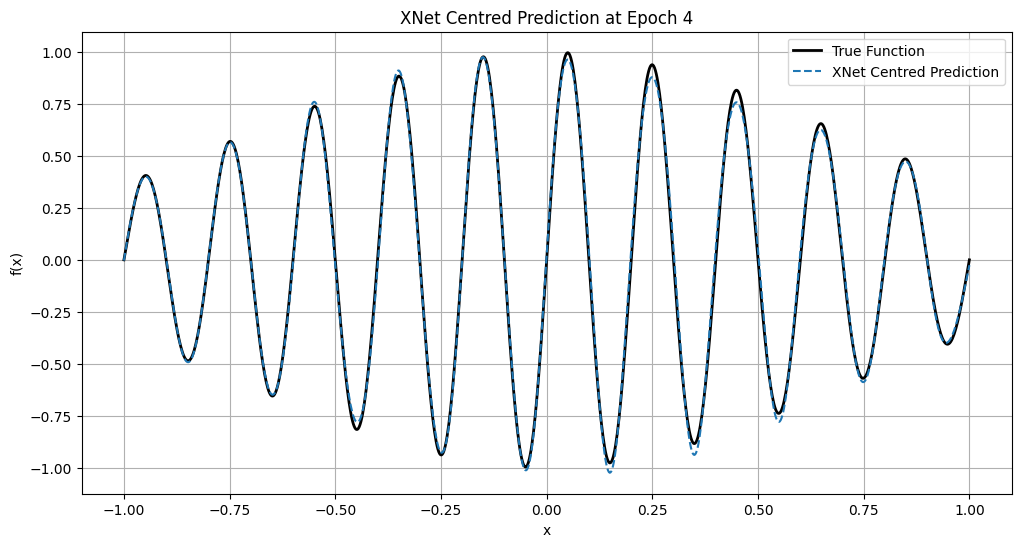

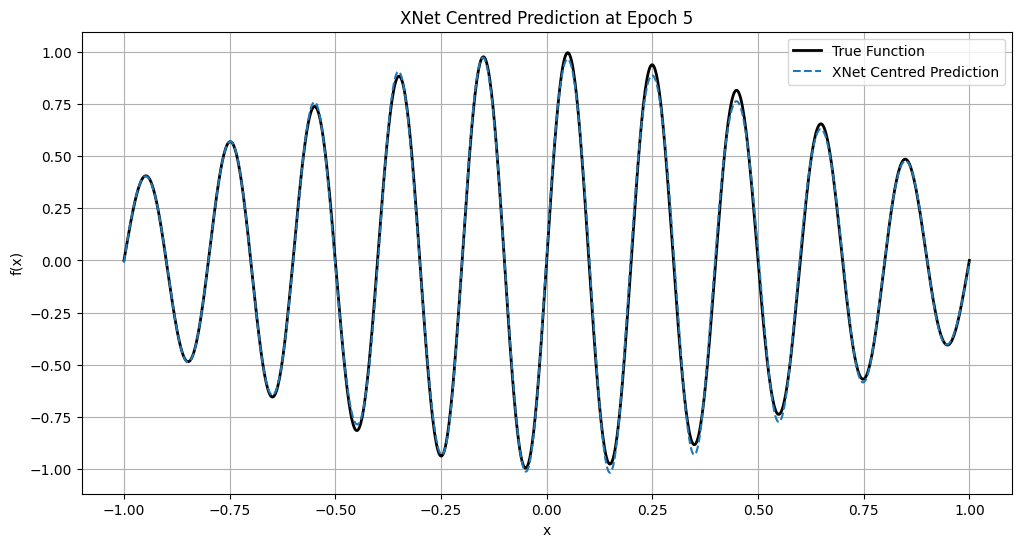

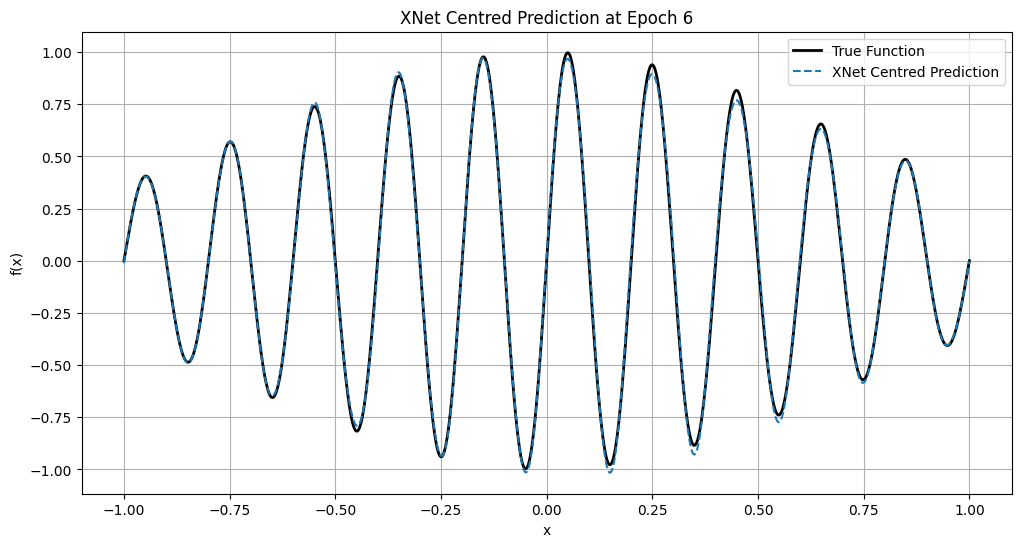

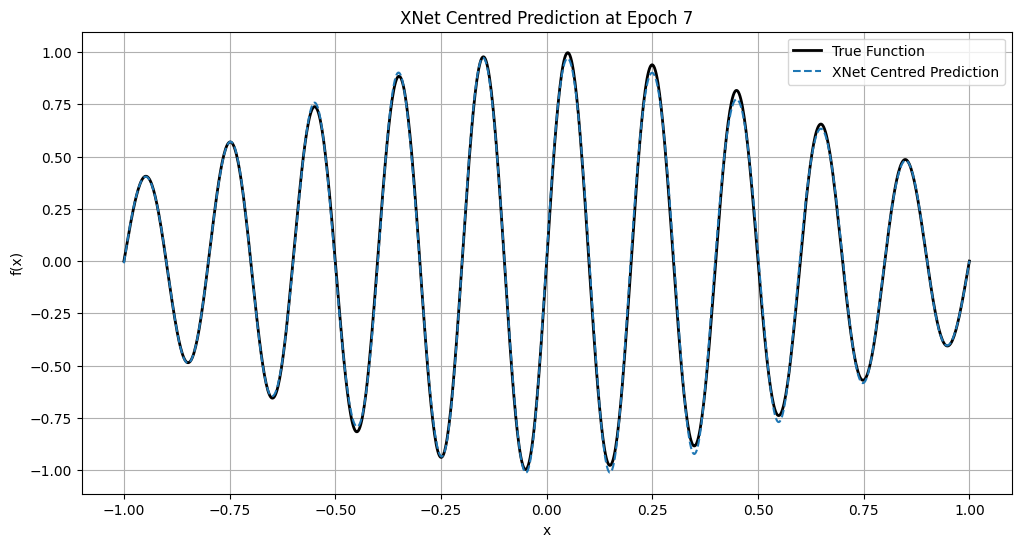

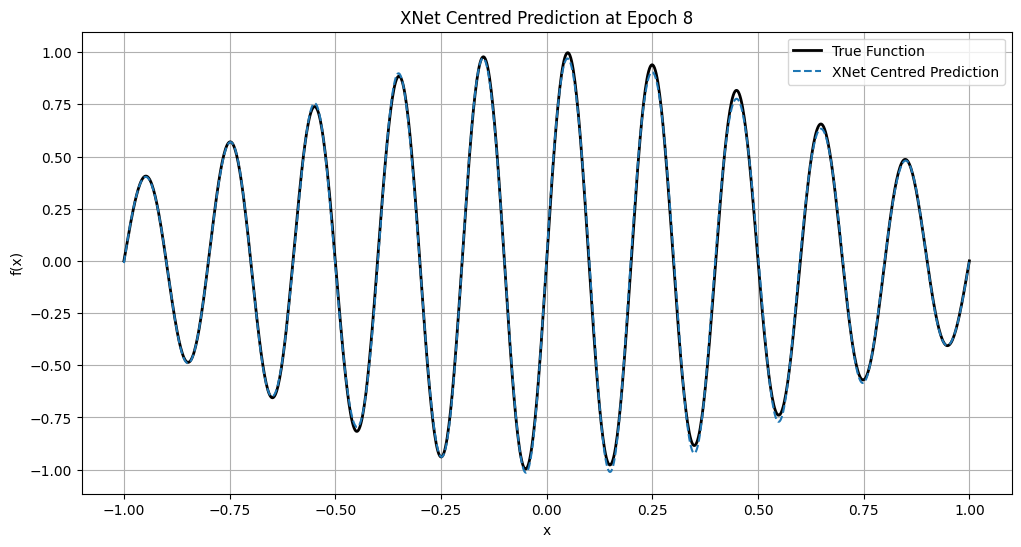

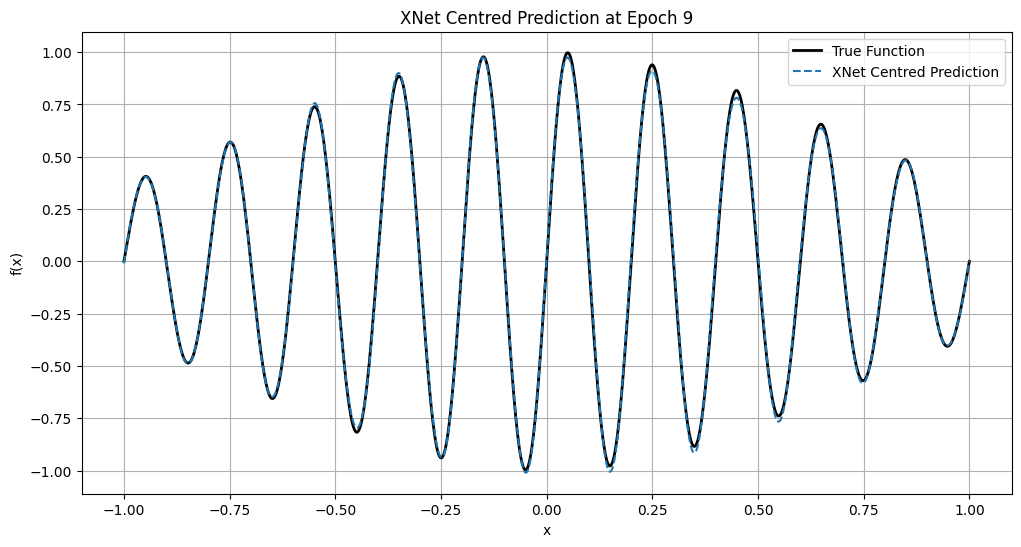

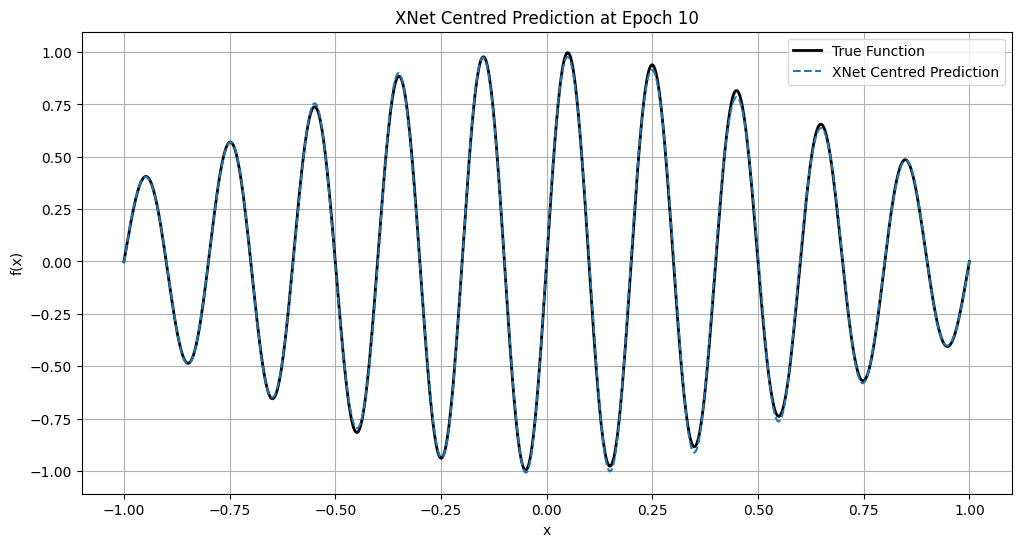

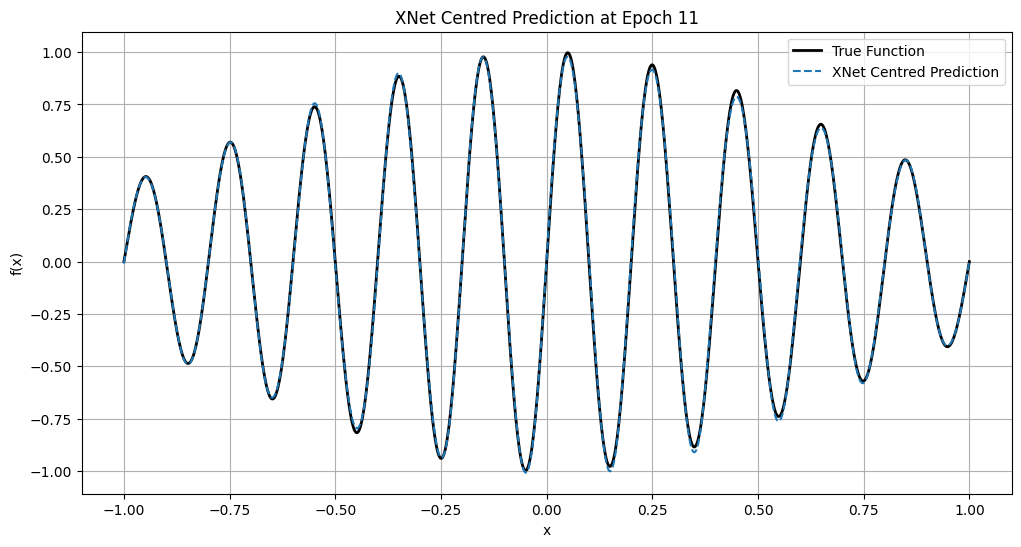

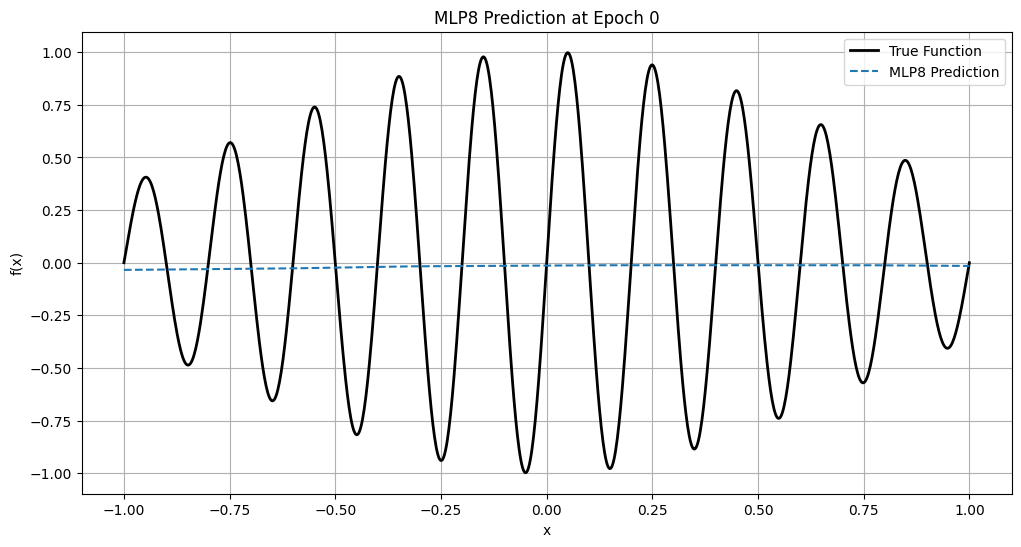

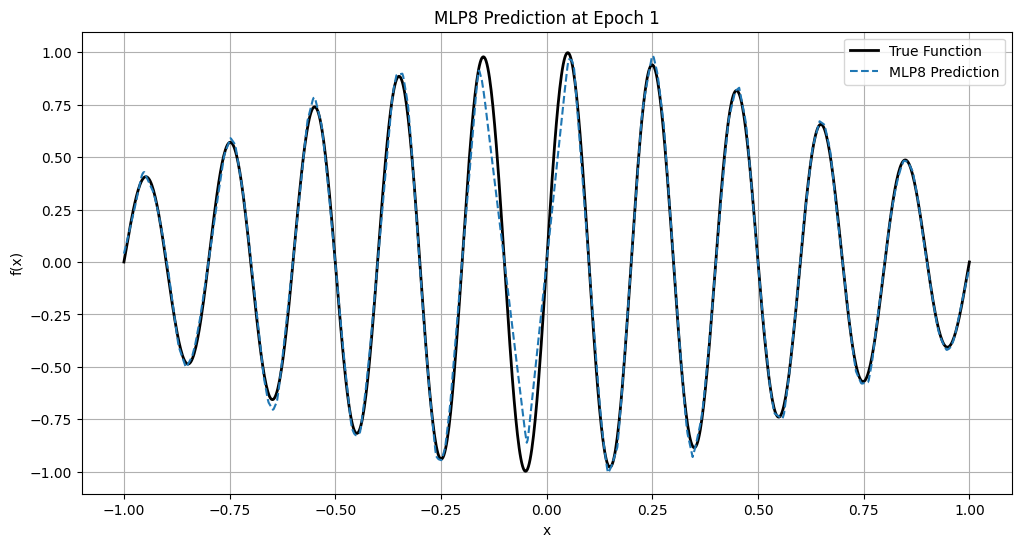

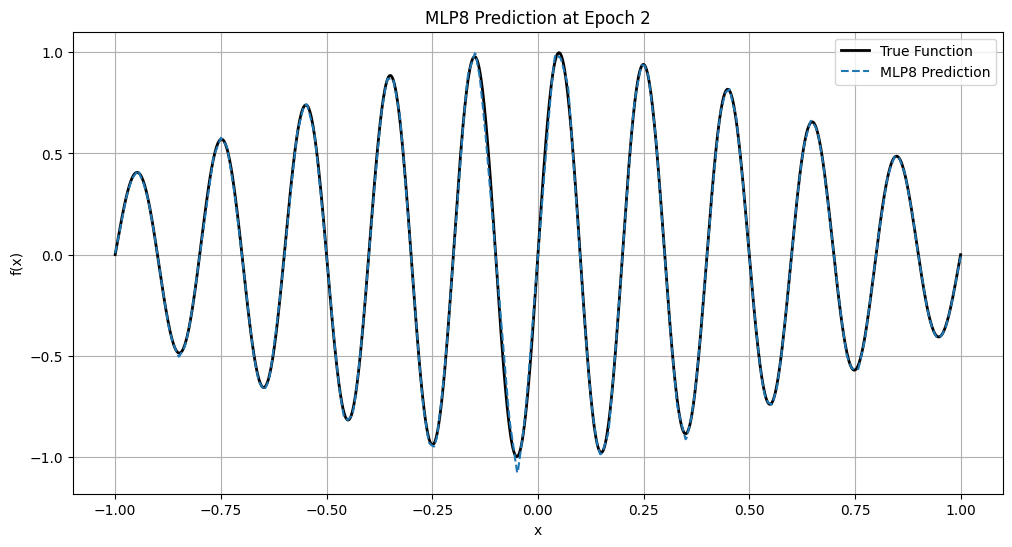

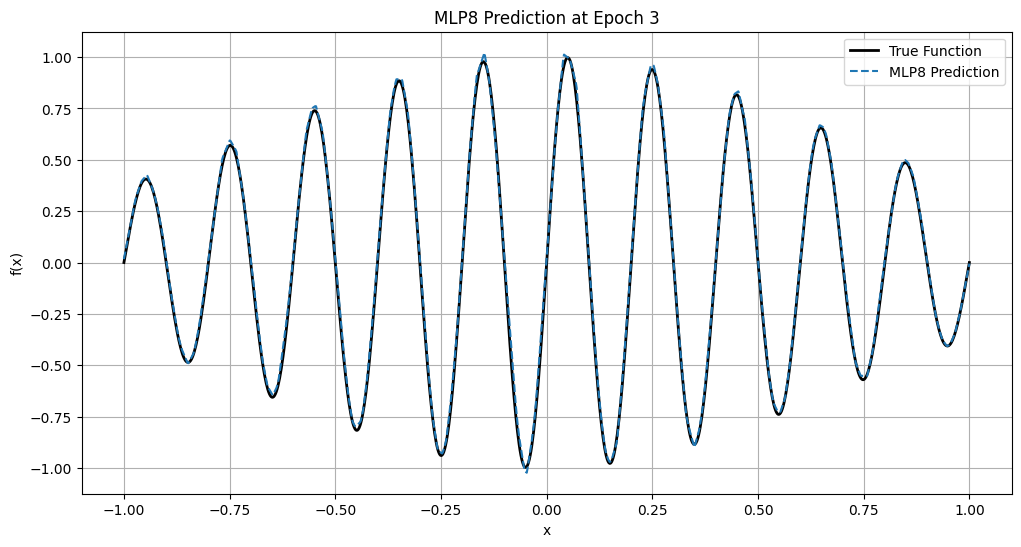

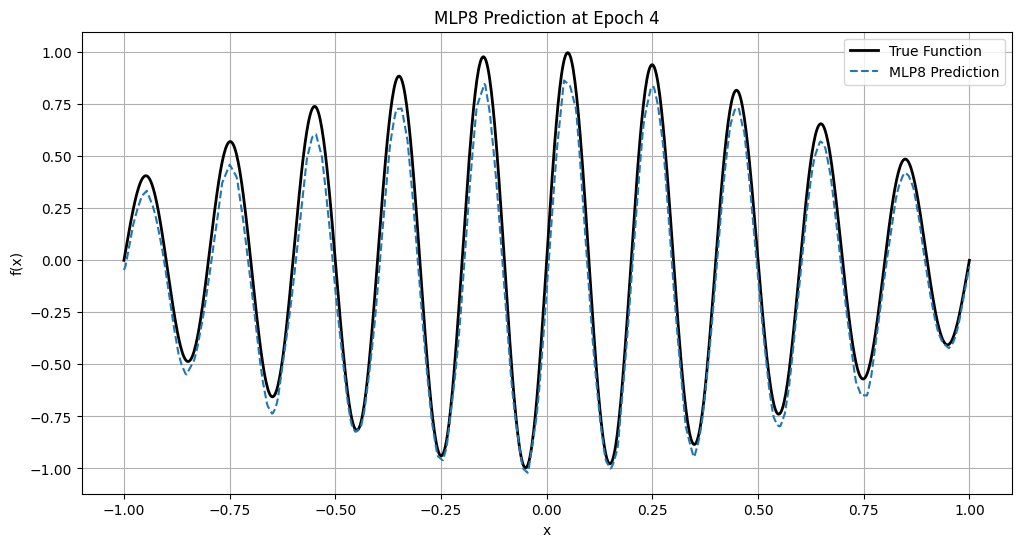

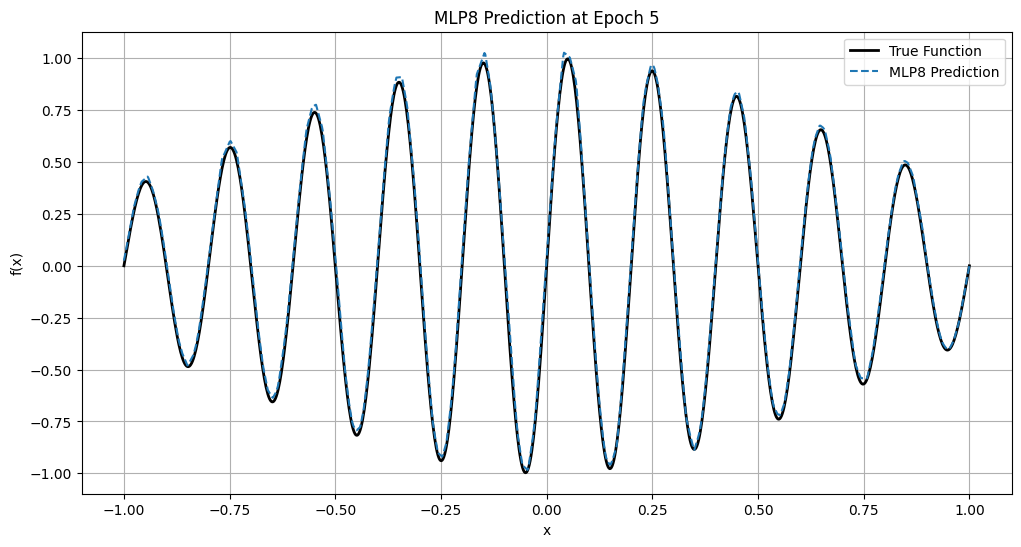

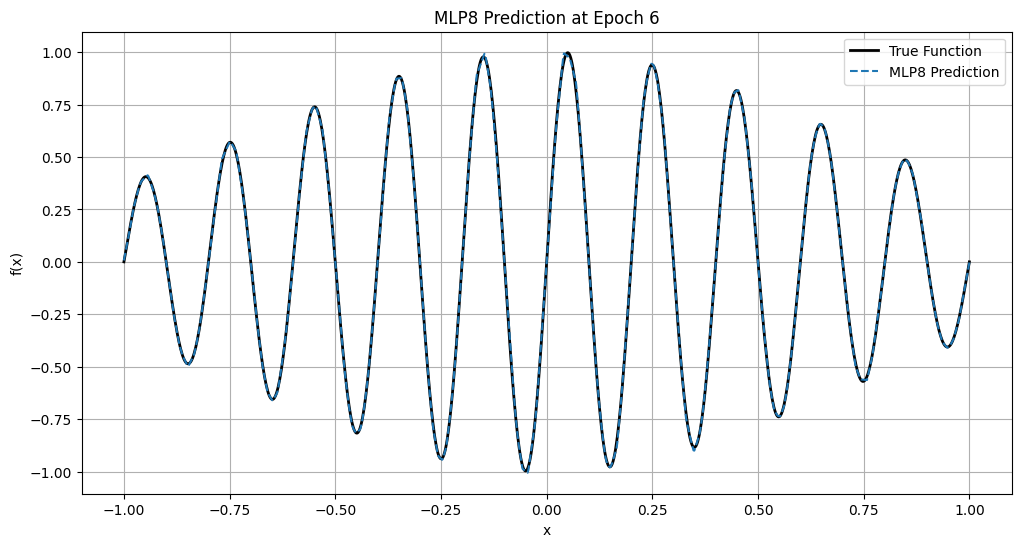

In [31]:
# plotar a evolução das predições do modelo ao longo das épocas de treinamento em imgaens diferentes
def plot_predictions_over_epochs(predictions, x_test, y_test, model_name):
    for epoch in range(len(predictions)):
        plt.figure(figsize=(12, 6))
        plt.clf()
        plt.plot(x_test.numpy(), y_test.numpy(), label='True Function', color='black', linewidth=2)
        plt.plot(x_test.numpy(), predictions[epoch], label=f'{model_name} Prediction', linestyle='--')
        plt.title(f'{model_name} Prediction at Epoch {epoch}')
        plt.xlabel('x')
        plt.ylabel('f(x)')
        plt.legend()
        plt.grid()
        plt.pause(0.01)  # Pause to update the plot

x_test = torch.linspace(-1, 1, 1000).unsqueeze(1)
y_test = f(x_test)
plot_predictions_over_epochs(predictions_xnet_centred, x_test, y_test, 'XNet Centred')
plot_predictions_over_epochs(predictions_mlp8, x_test, y_test, 'MLP8')    

Plotando cada curva individualmente, para ver a contribuição de cada uma delas na aproximação final.

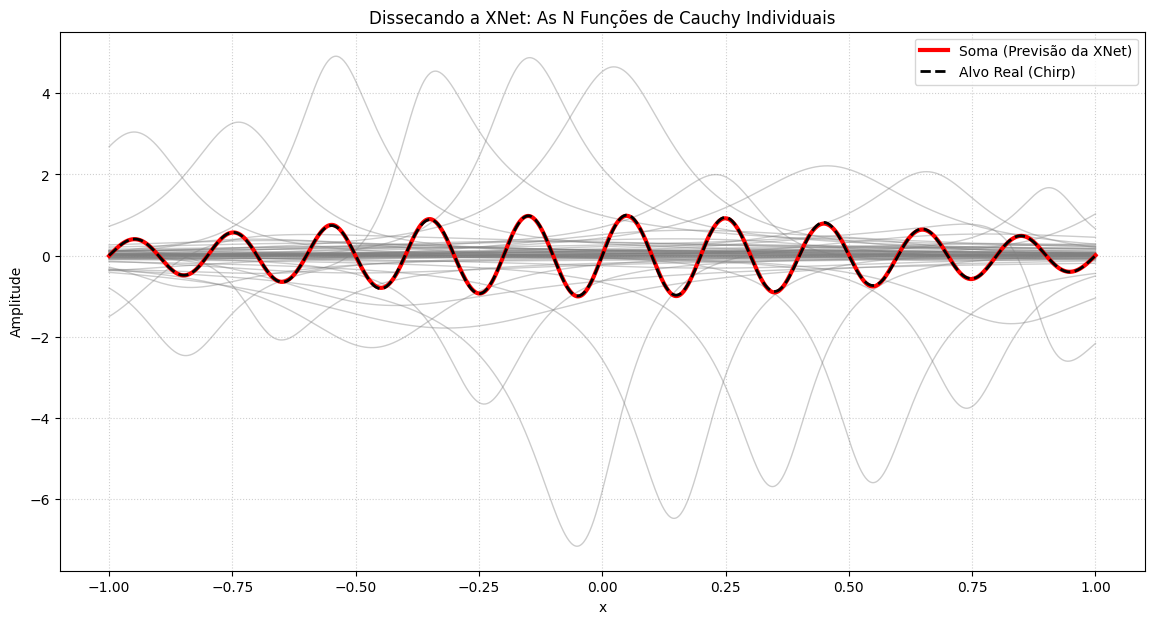

In [10]:
x_plot = torch.linspace(-1, 1, 1000)

d_vals = model_xnet_centred.d.detach()
l1_vals = model_xnet_centred.lambda1.detach()
l2_vals = model_xnet_centred.lambda2.detach()
c_vals = model_xnet_centred.centers.detach()

pesos_lineares = model_xnet_centred.output_linear.weight.detach().squeeze()
bias_linear = model_xnet_centred.output_linear.bias.detach().item()

plt.figure(figsize=(14, 7))

# 3. Calcular e plotar cada uma das N funções individualmente
soma_total = torch.zeros_like(x_plot) + bias_linear

for i in range(model_xnet_centred.num_basis):
    # Calcular a função de Cauchy iterativa para a base 'i'
    x_shifted = x_plot - c_vals[i]
    denom = x_shifted**2 + d_vals[i]**2
    phi_i = (l1_vals[i] * x_shifted) / denom + (l2_vals[i]) / denom
    
    # A contribuição final da base é a ativação multiplicada pelo peso da camada linear
    contribuicao_real = phi_i * pesos_lineares[i]
    
    # Adicionamos à soma total
    soma_total += contribuicao_real
    
    # Plotar a curva individual (fina e semi-transparente)
    plt.plot(x_plot.numpy(), contribuicao_real.numpy(), color='gray', alpha=0.4, linewidth=1)

# 4. Plotar a soma de todas as funções (A previsão final da rede)
plt.plot(x_plot.numpy(), soma_total.numpy(), color='red', linewidth=3, label='Soma (Previsão da XNet)')

# 5. Plotar a função alvo original para comparar
y_true = torch.sin(10 * np.pi * x_plot) * torch.exp(-x_plot**2)
plt.plot(x_plot.numpy(), y_true.numpy(), color='black', linestyle='--', linewidth=2, label='Alvo Real (Chirp)')

plt.title('Dissecando a XNet: As N Funções de Cauchy Individuais')
plt.xlabel('x')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()